# Parte 1: Análise Exploratória dos Dados (EDA)

In [2]:
# importando bibliotecas
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
# lendo a base de dados
database = pd.read_csv("klike_challenge_dataset.csv")
database.head()

,campaign_id,date,platform,category,objective,target_audience_age,is_retargeting,video_duration_s,format,has_subtitle,...,clicks,ctr,cpc,spend,conversions,revenue,roas,avg_watch_time_s,engagement_rate,klike_score
0,KLK-0001,2024-01-01,Meta,Branding,awareness,18-24,False,NaN,vertical,True,...,5882,0.0390,0.82,4823.24,48,0.00,0.00,3.9,0.0446,63.6
1,KLK-0002,2024-03-22,LinkedIn,App Install,traffic,25-34,False,NaN,horizontal,True,...,493,0.0664,3.54,1745.22,34,NaN,0.16,6.4,0.0217,70.0
2,KLK-0003,2024-05-04,TikTok,SaaS,traffic,25-34,False,8.0,vertical,True,...,15069,0.0780,0.38,5726.22,492,51053.44,8.92,8.0,0.1000,99.1
3,KLK-0004,2024-12-27,TikTok,Lead Gen,engagement,25-34,False,27.0,quadrado,False,...,601,0.0925,0.71,426.71,19,1113.78,2.61,20.3,0.0414,74.9
4,KLK-0005,2024-07-10,Meta,Branding,engagement,25-34,False,34.0,vertical,True,...,2355,0.0369,0.38,894.90,13,0.00,0.00,34.0,0.0184,77.9


## Primeira Etapa:  Perfil Geral dos Dados

### Análise da tipagem das variáveis

In [3]:
# Conferindo os valores de cada variável antes da mudança de tipo
change_col = ['platform', 'category', 'objective', 'format', 'text_density', 'target_audience_age', 'has_subtitle']
for coluna in change_col:
    display(database[coluna].value_counts(sort=False, dropna=False))

platform
Meta        241
LinkedIn     83
TikTok      176
Name: count, dtype: int64

category
Branding        63
App Install     82
SaaS            97
Lead Gen        93
E-commerce     165
Name: count, dtype: int64

objective
awareness       60
traffic        150
engagement      79
conversions    165
app_install     46
Name: count, dtype: int64

format
vertical      269
horizontal    111
quadrado      120
Name: count, dtype: int64

text_density
medium    230
low       179
high       91
Name: count, dtype: int64

target_audience_age
18-24    137
25-34    143
35-44    139
45+       81
Name: count, dtype: int64

has_subtitle
True     263
False    191
NaN       46
Name: count, dtype: int64

In [4]:
# Mudando o tipo de cada variável
database['has_subtitle'] = database['has_subtitle'].astype('boolean')
database['date'] = pd.to_datetime(database['date'])
cols_nominais = ['platform', 'category', 'objective', 'format']
database[cols_nominais] = database[cols_nominais].astype('category')
database['text_density'] = pd.Categorical(database['text_density'], categories=['low', 'medium', 'high'], ordered=True)
database['target_audience_age'] = pd.Categorical(database['target_audience_age'], categories=['18-24', '25-34', '35-44', '45+'], ordered=True)
database.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   campaign_id          500 non-null    str           
 1   date                 500 non-null    datetime64[us]
 2   platform             500 non-null    category      
 3   category             500 non-null    category      
 4   objective            500 non-null    category      
 5   target_audience_age  500 non-null    category      
 6   is_retargeting       500 non-null    bool          
 7   video_duration_s     461 non-null    float64       
 8   format               500 non-null    category      
 9   has_subtitle         454 non-null    boolean       
 10  has_cta              500 non-null    bool          
 11  has_hook             500 non-null    bool          
 12  has_face             500 non-null    bool          
 13  text_density         500 non-null    category 

In [6]:
# Mesmo código feito anteriormente. Aqui, comparamso com antes para ver
# se os valores e mantiveram
change_col = ['platform', 'category', 'objective', 'format', 'text_density', 'target_audience_age', 'has_subtitle']
for coluna in change_col:
    display(database[coluna].value_counts(sort=False, dropna=False))

platform
LinkedIn     83
Meta        241
TikTok      176
Name: count, dtype: int64

category
App Install     82
Branding        63
E-commerce     165
Lead Gen        93
SaaS            97
Name: count, dtype: int64

objective
app_install     46
awareness       60
conversions    165
engagement      79
traffic        150
Name: count, dtype: int64

format
horizontal    111
quadrado      120
vertical      269
Name: count, dtype: int64

text_density
low       179
medium    230
high       91
Name: count, dtype: int64

target_audience_age
18-24    137
25-34    143
35-44    139
45+       81
Name: count, dtype: int64

has_subtitle
True     263
False    191
<NA>      46
Name: count, dtype: Int64

### Valores Faltantes

In [7]:
# Cálculo dos valores Null/NaN por coluna na base de dados
missing_df = pd.DataFrame({'Total Ausentes': database.isna().sum(), 'Porcentagem (ausentes por coluna, %)': (database.isna().sum() / len(database['campaign_id']) * 100).round(1)})

missing_df = missing_df[missing_df['Total Ausentes'] > 0].sort_values(by='Total Ausentes', ascending=False)
missing_df['Total Ausentes'] = missing_df["Total Ausentes"].astype("int")
display(missing_df)
print(f"Linhas com pelo menos um nulo: {database.isna().any(axis=1).mean():.1%}")


,Total Ausentes,"Porcentagem (ausentes por coluna, %)"
has_subtitle,46,9.2
video_duration_s,39,7.8
music_voice_ratio,38,7.6
engagement_rate,32,6.4
cpc,28,5.6
avg_watch_time_s,27,5.4
revenue,25,5.0


Linhas com pelo menos um nulo: 38.2%


| Coluna | Tratamento |
|---|---|
| `cpc`, `revenue` | Podem ser **reconstruídas** pelas identidades `cpc = spend / clicks` e `revenue = roas × spend` (validadas nas linhas completas) |
| `has_subtitle`, `video_duration_s`, `music_voice_ratio`, `avg_watch_time_s`, `engagement_rate` | Imputação pela **mediana** (aplicada na etapa de modelagem) |

### Análise de distribuição e assimetria

In [8]:
# Separando as colunas quantitativas
cols_quant = database.select_dtypes(include=['float64', 'int64']).columns 
# Analisando métricas fundamentais das colunas quantitativas do banco
dist_quant = pd.DataFrame({
    'Média': database[cols_quant].mean(),
    'Mediana': database[cols_quant].median(),
    'Desvio Padrão': database[cols_quant].std(),
    'Mínimo': database[cols_quant].min(),
    'Máximo': database[cols_quant].max(),
    'Assimetria (Skew)': database[cols_quant].skew()
}).round(2)
dist_quant.sort_values(by='Assimetria (Skew)', ascending=False)


,Média,Mediana,Desvio Padrão,Mínimo,Máximo,Assimetria (Skew)
impressions,153738.52,23241.00,1171735.61,1000.00,14052761.00,11.00
cpc,1.11,0.71,1.96,0.05,26.05,9.93
revenue,6367.94,1201.05,19267.18,0.00,241597.29,8.34
conversions,131.35,34.50,314.57,0.00,3666.00,6.03
spend,4213.15,1031.00,11573.98,2.96,121226.10,5.94
clicks,3594.10,1351.00,7018.21,4.00,72545.00,5.17
roas,2.50,1.49,3.59,0.00,39.92,4.40
avg_watch_time_s,10.66,7.70,10.53,0.40,108.00,4.01
video_duration_s,19.39,16.00,13.53,5.00,115.00,2.56
engagement_rate,0.03,0.02,0.02,0.00,0.10,1.31


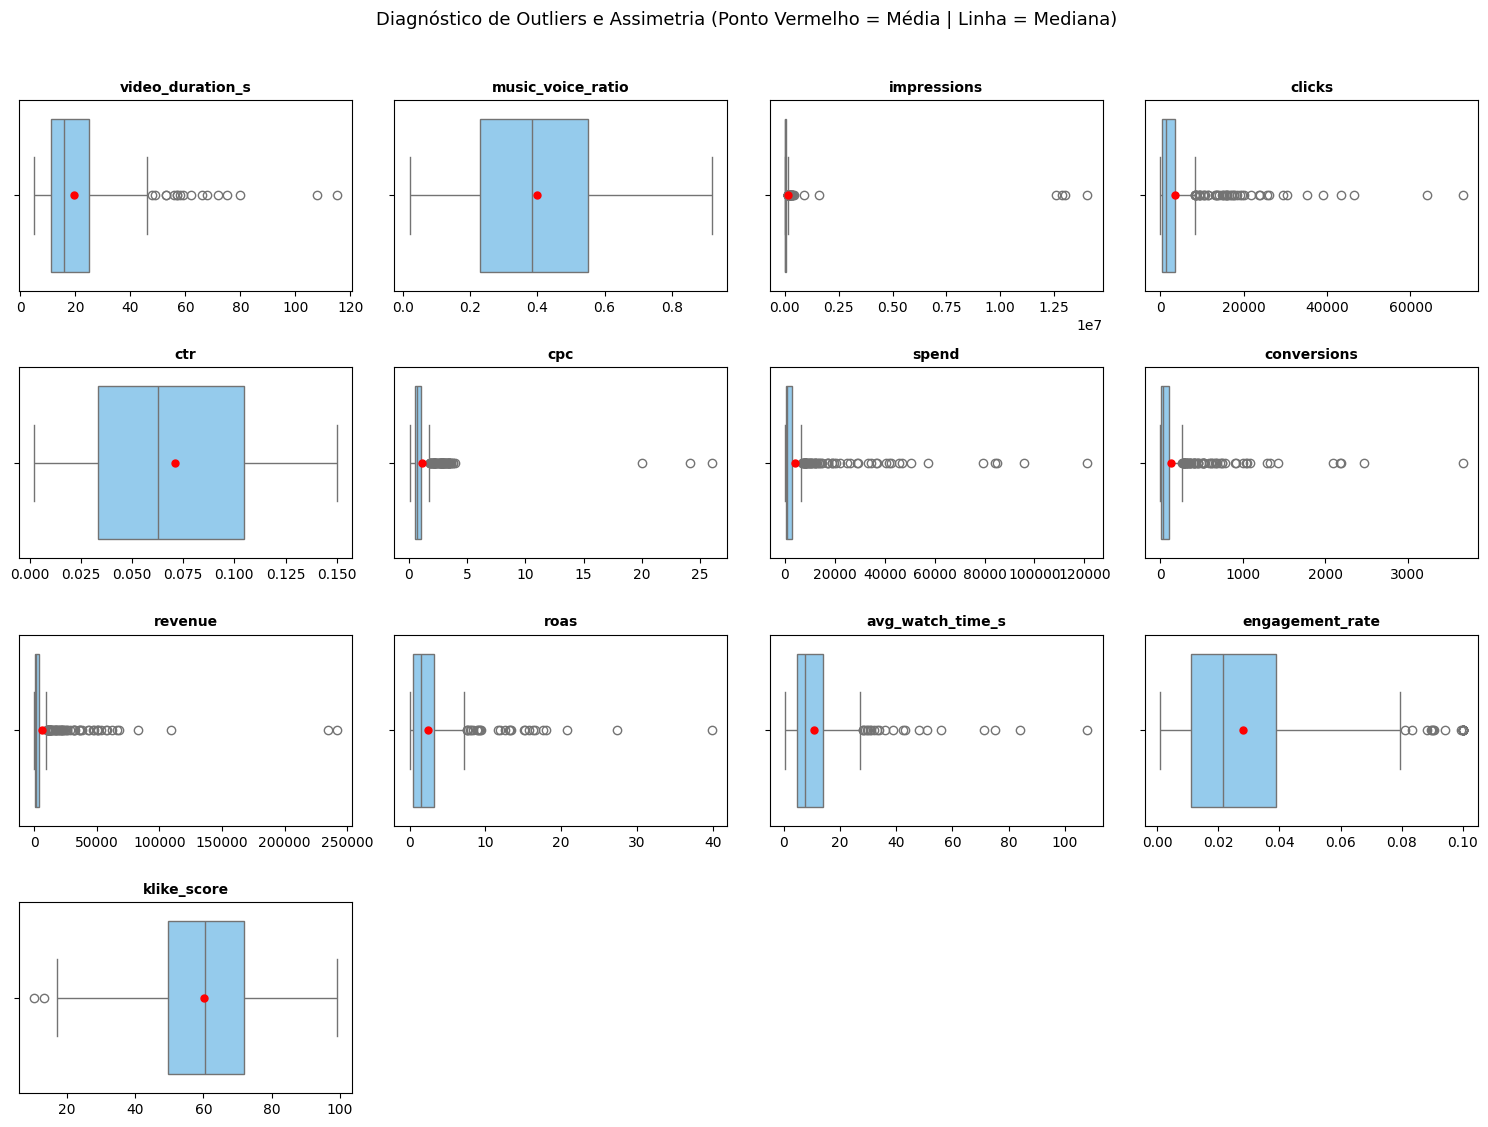

In [ ]:
# Definindo o "espaço" de plotagem dos gráficos
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
axes = axes.flatten()
for col, ax in zip(cols_quant, axes):
    # criando um gráfico boxplot para cada coluna quantitativa
    sns.boxplot(
        x=database[col].dropna(), 
        ax=ax, 
        color='lightskyblue', 
        showmeans=True,
        meanprops={'marker':'o', 'markerfacecolor':'red', 'markeredgecolor':'red', 'markersize': 5}
    )
    ax.set_title(col, fontweight='bold', fontsize=10)
    ax.set_xlabel('')
for ax in axes[len(cols_quant):]:
    ax.set_visible(False)
plt.suptitle("Diagnóstico de Outliers e Assimetria (Ponto Vermelho = Média | Linha = Mediana)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


In [9]:
# Lista de todas as variáveis qualitativas
cols_quali = ['platform', 'category', 'objective', 'format', 'text_density', 'target_audience_age', 'is_retargeting', 'has_cta', 'has_hook', 'has_face', 'has_subtitle']

# Exibindo contagem e proporção de cada variável utilizando value_counts
for col in cols_quali:
    contagem = database[col].value_counts(dropna=False)
    percentual = (database[col].value_counts(dropna=False, normalize=True) * 100).round(1)
    
    tabela_cat = pd.DataFrame({'Contagem': contagem, 'Proporção (%)': percentual})
    print(f"=== {col} ===")
    print(tabela_cat)
    print("-" * 35)


=== platform ===
          Contagem  Proporção (%)
platform                         
Meta           241           48.2
TikTok         176           35.2
LinkedIn        83           16.6
-----------------------------------
=== category ===
             Contagem  Proporção (%)
category                            
E-commerce        165           33.0
SaaS               97           19.4
Lead Gen           93           18.6
App Install        82           16.4
Branding           63           12.6
-----------------------------------
=== objective ===
             Contagem  Proporção (%)
objective                           
conversions       165           33.0
traffic           150           30.0
engagement         79           15.8
awareness          60           12.0
app_install        46            9.2
-----------------------------------
=== format ===
            Contagem  Proporção (%)
format                             
vertical         269           53.8
quadrado         120         

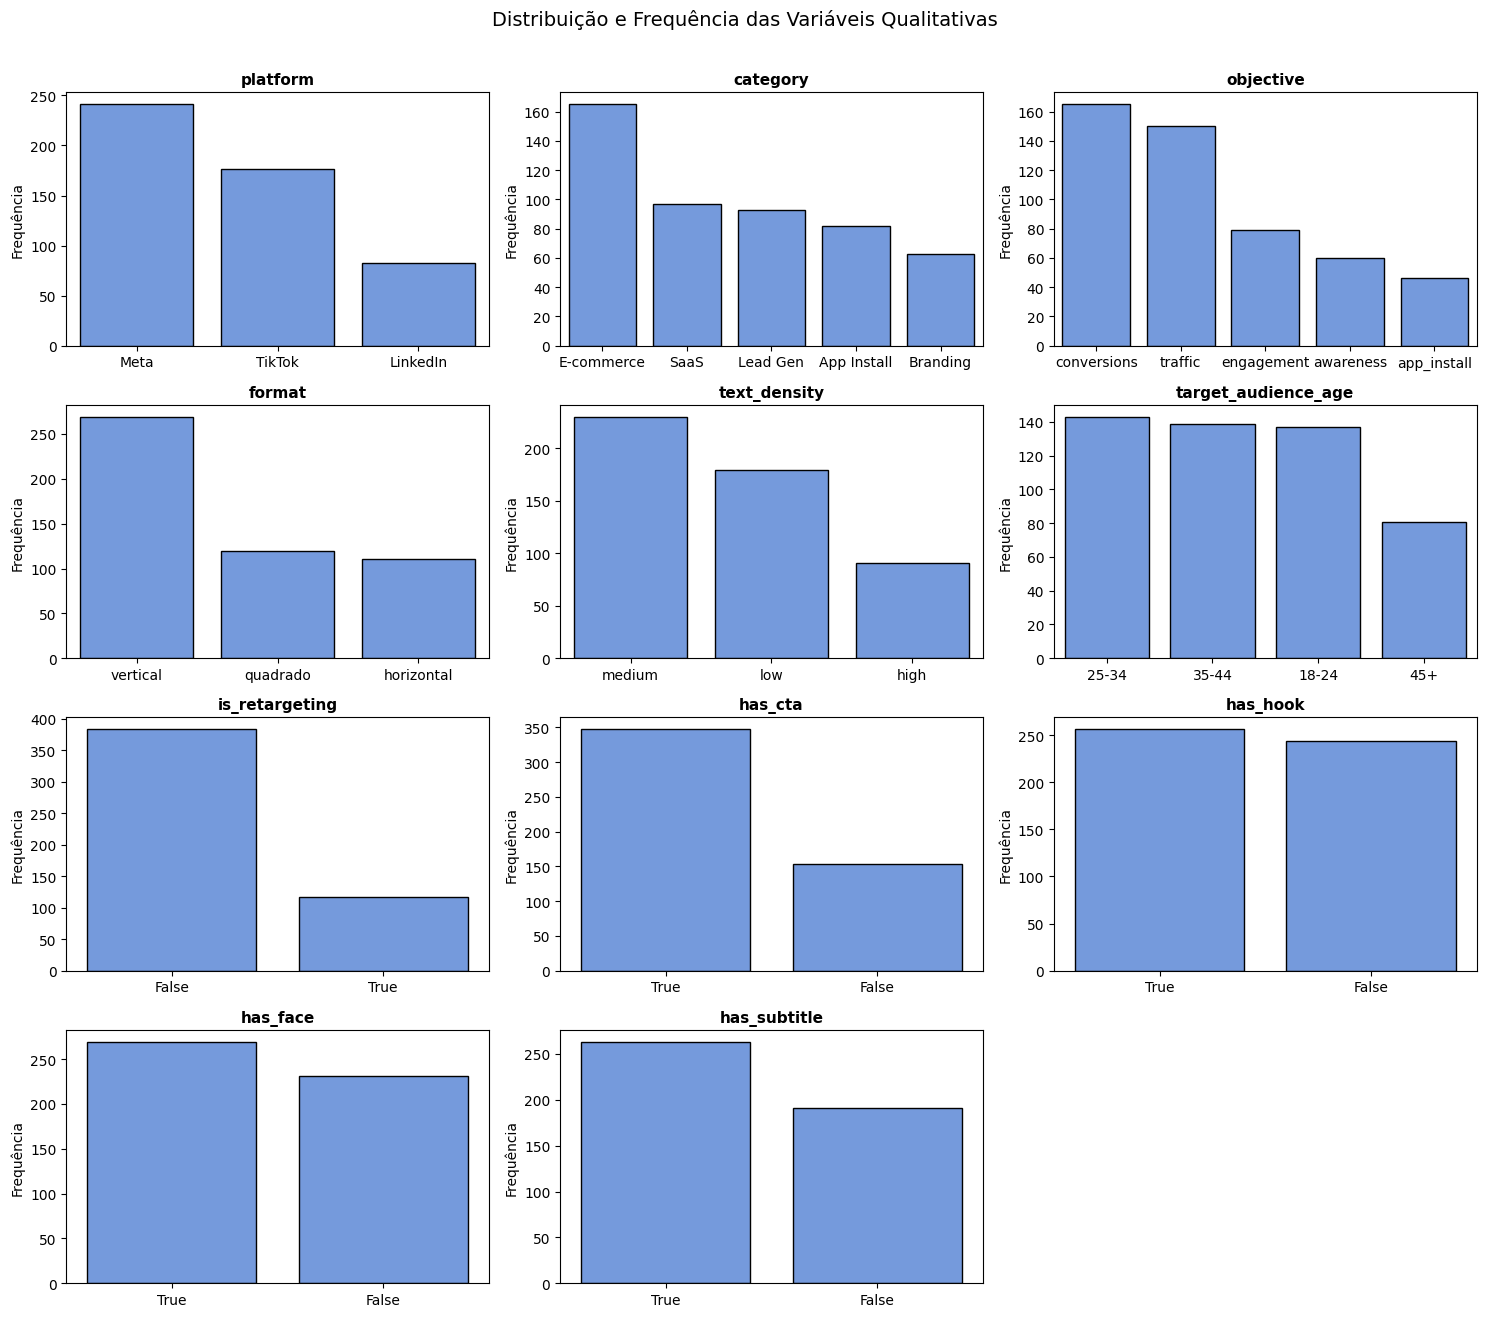

In [11]:
# 2. Cria a grade 4x3 de espaço para plotar gráficos
fig, axes = plt.subplots(4, 3, figsize=(15, 13))
axes = axes.flatten()

# 3. Plota o gráfico de barras para cada variável
for col, ax in zip(cols_quali, axes):
    # cria um gráfico de frequência para cada variável
    ordem = database[col].value_counts().index
    sns.countplot(data=database, x=col, ax=ax, order=ordem, color='cornflowerblue', edgecolor='black')
    
    ax.set_title(col, fontweight='bold', fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('Frequência')

axes[-1].set_visible(False)

plt.suptitle("Distribuição e Frequência das Variáveis Qualitativas", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


## Segunda Etapa: Atributos do Criativo X Métricas de Performance

### Atributos Binários 

In [12]:
binary_features = ['has_hook', 'has_face', 'has_cta', 'has_subtitle']
success_metrics = ['klike_score', 'avg_watch_time_s', 'ctr', 'engagement_rate']

summary_rows = []
for feature in binary_features:
    # para cada feature binaria
    for metric in success_metrics:
        # calcula a média das métricas de sucesso com base no valor binário da variável (True ou False)
        mean_false = database[database[feature] == False][metric].mean()
        mean_true = database[database[feature] == True][metric].mean()
        diff = mean_true - mean_false
        lift_pct = (diff / mean_false) * 100
        
        if metric in ['ctr', 'engagement_rate']:
            val_false_str = f"{mean_false * 100:.2f}%"
            val_true_str = f"{mean_true * 100:.2f}%"
            diff_str = f"{diff * 100:+.2f} p.p."
        else:
            val_false_str = f"{mean_false:.2f}"
            val_true_str = f"{mean_true:.2f}"
            diff_str = f"{diff:+.2f}"
            
        summary_rows.append({
            'Recurso': feature,
            'Metrica': metric,
            'Sem o Recurso (False)': val_false_str,
            'Com o Recurso (True)': val_true_str,
            'Diferença absoluta (Com - Sem)': diff_str,
            'Ganho relativo (%)': f"{lift_pct:+.1f}%"
        })

df_binary_summary = pd.DataFrame(summary_rows)
df_binary_summary


,Recurso,Metrica,Sem o Recurso (False),Com o Recurso (True),Diferença absoluta (Com - Sem),Ganho relativo (%)
0,has_hook,klike_score,51.39,68.52,+17.13,+33.3%
1,has_hook,avg_watch_time_s,8.76,12.47,+3.70,+42.3%
2,has_hook,ctr,5.91%,8.23%,+2.32 p.p.,+39.2%
3,has_hook,engagement_rate,2.53%,3.04%,+0.51 p.p.,+20.3%
4,has_face,klike_score,53.66,65.73,+12.07,+22.5%
5,has_face,avg_watch_time_s,9.32,11.80,+2.48,+26.6%
6,has_face,ctr,6.32%,7.76%,+1.44 p.p.,+22.8%
7,has_face,engagement_rate,2.32%,3.21%,+0.89 p.p.,+38.2%
8,has_cta,klike_score,54.57,62.62,+8.05,+14.8%
9,has_cta,avg_watch_time_s,10.41,10.78,+0.37,+3.5%


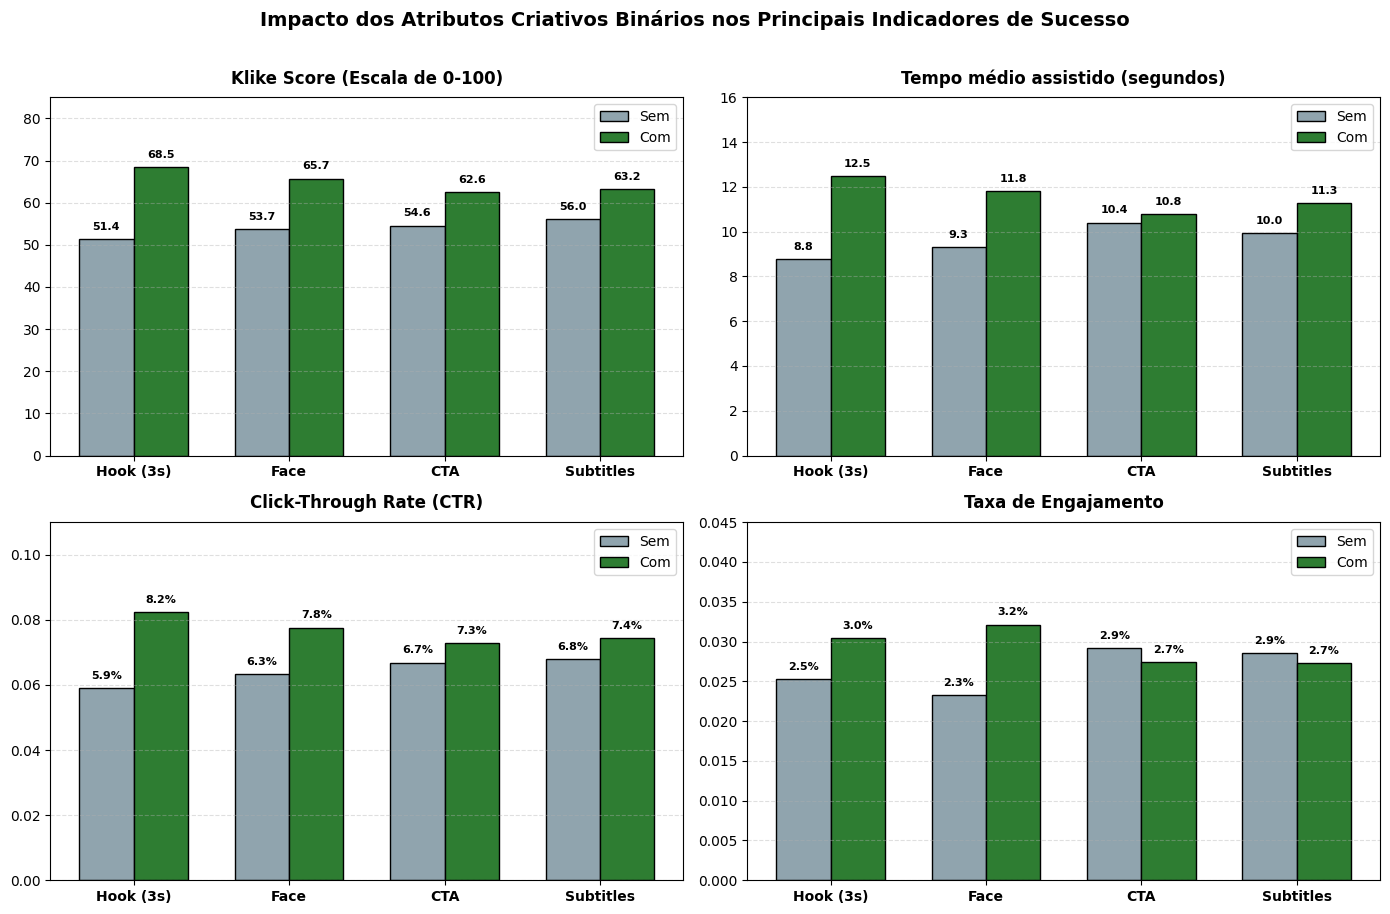

In [13]:
# 1. Rótulos amigáveis para exibir no eixo X de cada gráfico
feature_labels = ['Hook (3s)', 'Face', 'CTA', 'Subtitles']

# 2. Configurações visuais de cada métrica:
# Formato: (coluna_no_df, titulo_do_subplot, unidade_de_medida, limite_inferior_y, limite_superior_y)
metrics_config = [
    ('klike_score', 'Klike Score (Escala de 0-100)', 'pts', 0, 85),
    ('avg_watch_time_s', 'Tempo médio assistido (segundos)', 's', 0, 16),
    ('ctr', 'Click-Through Rate (CTR)', '%', 0, 0.11),
    ('engagement_rate', 'Taxa de Engajamento', '%', 0, 0.045)
]

# 3. Criação da grade de gráficos 2x2 para os gráficos
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

# 4. Loop para construir cada um dos 4 subplots de métricas
for ax, (metric, title, unit, y_min, y_max) in zip(axes, metrics_config):
    
    # Calcula a média da métrica quando o criativo NÃO possui o recurso (False)
    vals_without = [database[database[f] == False][metric].mean() for f in binary_features]
    
    # Calcula a média da métrica quando o criativo POSSUI o recurso (True)
    vals_with = [database[database[f] == True][metric].mean() for f in binary_features]
    
    x_positions = range(len(binary_features))
    bar_width = 0.35
    
    # Plota as barras lado a lado:
    # - Barras cinzas: anúncios SEM o recurso (deslocadas ligeiramente à esquerda)
    bars_without = ax.bar([i - bar_width/2 for i in x_positions], vals_without, width=bar_width, 
                          label='Sem', color='#90a4ae', edgecolor='black')
    # - Barras verdes: anúncios COM o recurso (deslocadas ligeiramente à direita)
    bars_with = ax.bar([i + bar_width/2 for i in x_positions], vals_with, width=bar_width, 
                       label='Com', color='#2e7d32', edgecolor='black')
    
    # Customização estética do subplot
    ax.set_title(title, fontweight='bold', fontsize=12, pad=10)
    ax.set_xticks(x_positions)
    ax.set_xticklabels(feature_labels, fontweight='bold', fontsize=10)
    ax.set_ylim(y_min, y_max)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.legend(loc='upper right')

    # Adiciona rótulos de dados (data labels) com os valores em cima de cada barra
    for bar in bars_without + bars_with:
        height = bar.get_height()
        # Formata como porcentagem com 1 casa decimal se a unidade for '%', ou número decimal se for ponto/segundo
        label_text = f"{height * 100:.1f}%" if unit == '%' else f"{height:.1f}"
        
        ax.text(bar.get_x() + bar.get_width()/2., height + (y_max - y_min) * 0.02, label_text, 
                ha='center', va='bottom', fontsize=8, fontweight='bold')

# Título global do painel e ajuste do espaçamento entre os subplots
plt.suptitle('Impacto dos Atributos Criativos Binários nos Principais Indicadores de Sucesso', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


Com base na tabela e gráfico acima, pode-se chegar nas seguintes conclusões: 

1. **`has_hook` (Gancho nos Primeiros 3 Segundos):**
   - **Retenção (`avg_watch_time_s`):** Salta de **8.76s para 12.47s (+42.3%)**.
   - **CTR (Taxa de Cliques):** Sobe de **5.91% para 8.23% (+39.2%)** (+2.32 p.p.).
   - **Qualidade Geral (`klike_score`):** Aumenta de **51.39 para 68.52 (+33.3%)** (+17.13 pontos).
   - **Insight de Negócio:** Prender a atenção nos primeiros 3 segundos impede que o usuário deslize o feed antes da mensagem principal, gerando um efeito cascata que impacta de forma positiva as métricas do criativo

2. **`has_face` (Presença de Rosto Humano):**
   * **Engajamento (`engagement_rate`):** Dispara de **2.32% para 3.21% (+38.2%)** (+0.89 p.p.).
   * **CTR:** Cresce de **6.32% para 7.76% (+22.8%)** (+1.44 p.p.).
   * **Qualidade Geral (`klike_score`):** Sobe de **53.66 para 65.73 (+22.5%)** (+12.07 pontos).
   * **Insight de Negócio:** Vídeos com pessoas reais geram conexão emocional e identificação imediata, resultando em mais reações, comentários e cliques qualificados.

3. **`has_subtitle` (Legendas):**
   * **Retenção (`avg_watch_time_s`):** Eleva-se de **9.95s para 11.29s (+13.5%)** (+1.34s).
   * **Qualidade Geral (`klike_score`):** Sobe de **56.02 para 63.17 (+12.8%)** (+7.15 pontos).
   * **Insight de Negócio:** Grande parte dos usuários consome vídeos em redes sociais com o áudio desativado no feed. A legenda garante a transmissão da proposta de valor mesmo sem som.

4. **`has_cta` (Chamada para Ação Clara):**
   * **Qualidade Geral (`klike_score`):** Sobe de **54.57 para 62.62 (+14.8%)** (+8.05 pontos).
   * **CTR:** Cresce de **6.69% para 7.28% (+8.8%)** (+0.59 p.p.).
   * **Insight de Negócio:** O CTA tem menor impacto na retenção (já que costuma ficar no fim do vídeo), mas é indispensável para direcionar o usuário para a ação de conversão desejada.


### Atributos Categóricos

In [14]:
# Lista com os principais indicadores-chave de performance (KPIs) a serem avaliados
eval_metrics = ['klike_score', 'avg_watch_time_s', 'ctr', 'engagement_rate', 'roas']

# Agrupa pela densidade de texto, calcula a média de cada KPI e reordena as linhas
# seguindo a progressão lógica da variável ordinal: Baixo ('low') -> Médio ('medium') -> Alto ('high')
df_text_density = database.groupby('text_density', observed=False)[eval_metrics].mean().loc[['low', 'medium', 'high']]

# Cria uma cópia para aplicar formatação visual sem alterar os dados numéricos originais
df_text_density_styled = df_text_density.copy()

# Renomeia as colunas com termos em português mais claros para apresentação
df_text_density_styled.columns = ['Klike Score', 'Retenção Média (s)', 'CTR', 'Taxa Engajamento', 'ROAS']

# Converte métricas de taxa (CTR e Engajamento) de formato decimal para porcentagem com 2 casas decimais
df_text_density_styled['CTR'] = df_text_density_styled['CTR'].apply(lambda x: f"{x*100:.2f}%")
df_text_density_styled['Taxa Engajamento'] = df_text_density_styled['Taxa Engajamento'].apply(lambda x: f"{x*100:.2f}%")

# Arredonda as demais colunas contínuas (Score, Retenção e ROAS) para 2 casas decimais
df_text_density_styled = df_text_density_styled.round(2)

print("=== DESEMPENHO POR DENSIDADE DE TEXTO ===")
display(df_text_density_styled)

# Agrupa por formato de tela e calcula a média de cada KPI, ordenando por prevalência de consumo mobile:
# Vertical (mobile-first) -> Quadrado (feed híbrido) -> Horizontal (desktop/tradicional)
df_format = database.groupby('format', observed=False)[eval_metrics].mean().loc[['vertical', 'quadrado', 'horizontal']]

# Cria uma cópia para formatação de exibição
df_format_styled = df_format.copy()

# Renomeia as colunas com rótulos amigáveis em português
df_format_styled.columns = ['Klike Score', 'Retenção Média (s)', 'CTR', 'Taxa Engajamento', 'ROAS']

# Converte métricas de taxa para formato percentual visível
df_format_styled['CTR'] = df_format_styled['CTR'].apply(lambda x: f"{x*100:.2f}%")
df_format_styled['Taxa Engajamento'] = df_format_styled['Taxa Engajamento'].apply(lambda x: f"{x*100:.2f}%")

# Arredonda as colunas contínuas para 2 casas decimais
df_format_styled = df_format_styled.round(2)

print("\n=== DESEMPENHO POR FORMATO DO VÍDEO ===")
display(df_format_styled)


=== DESEMPENHO POR DENSIDADE DE TEXTO ===


,Klike Score,Retenção Média (s),CTR,Taxa Engajamento,ROAS
text_density,,,,,
low,58.66,11.50,7.39%,2.79%,2.80
medium,65.31,10.59,7.31%,2.84%,2.43
high,50.07,9.27,5.96%,2.70%,2.10



=== DESEMPENHO POR FORMATO DO VÍDEO ===


,Klike Score,Retenção Média (s),CTR,Taxa Engajamento,ROAS
format,,,,,
vertical,60.77,8.86,6.82%,3.29%,2.80
quadrado,59.65,11.31,7.30%,2.42%,2.91
horizontal,59.21,14.15,7.54%,1.96%,1.33


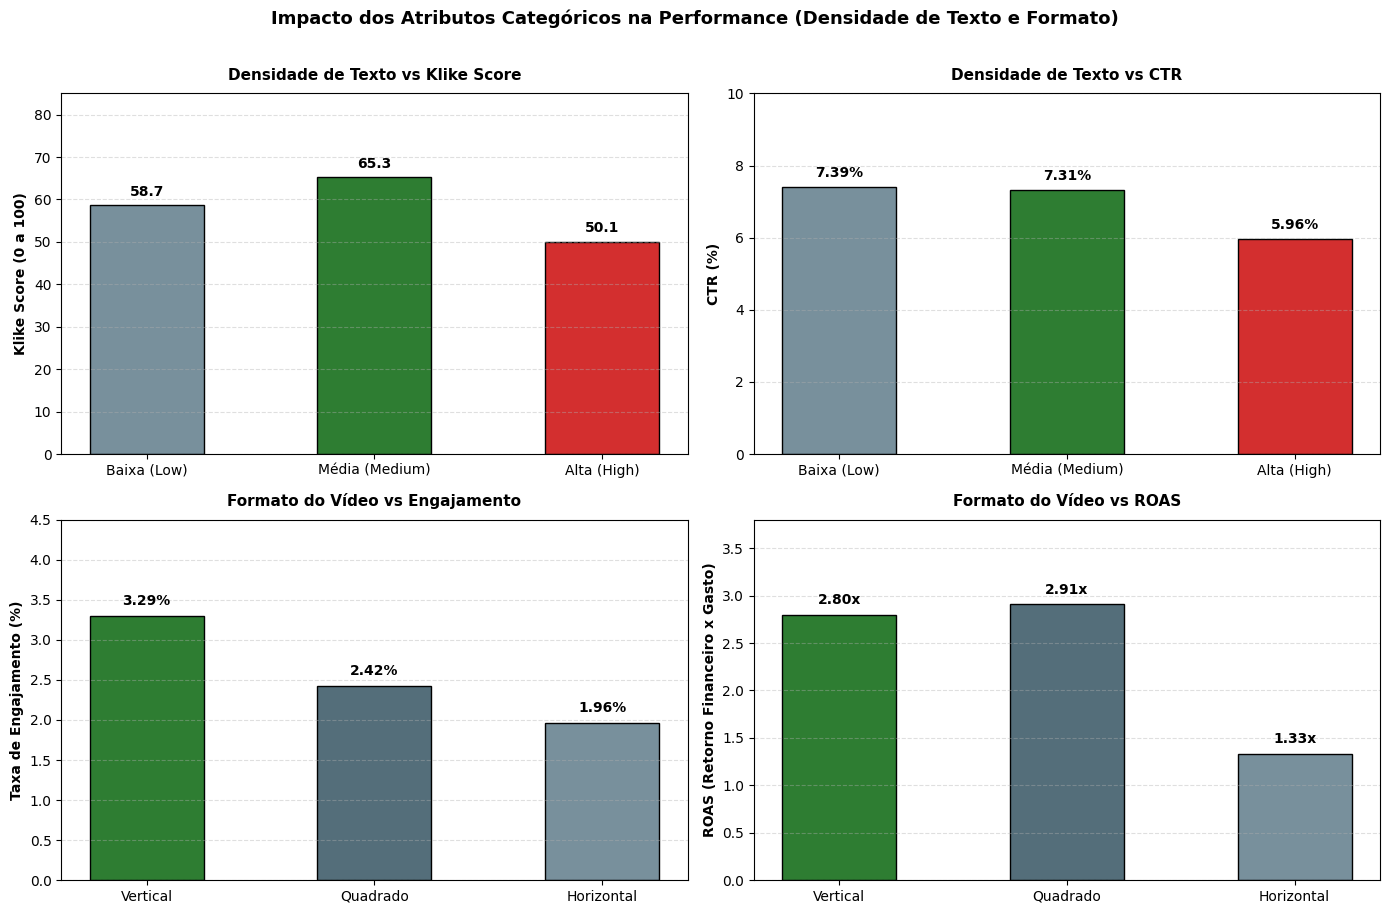

In [15]:
# Cria a grade de 2 linhas x 2 colunas para exibir o painel de atributos categóricos
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Define a ordenação lógica dos níveis de texto e os rótulos de exibição
order_td = ['low', 'medium', 'high']
labels_td = ['Baixa (Low)', 'Média (Medium)', 'Alta (High)']
means_score_td = df_text_density['klike_score']

# Paleta semântica: cinza (base), verde (pico de qualidade ótimo) e vermelho (penalidade severa)
colors_td = ['#78909c', '#2e7d32', '#d32f2f']

# Plota as barras de Klike Score por nível de densidade de texto
bars1 = axes[0, 0].bar(labels_td, means_score_td, color=colors_td, width=0.5, edgecolor='black')
axes[0, 0].set_title('Densidade de Texto vs Klike Score', fontweight='bold', fontsize=11, pad=10)
axes[0, 0].set_ylabel('Klike Score (0 a 100)', fontweight='bold')
axes[0, 0].set_ylim(0, 85)
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.4)

# Adiciona os rótulos com a pontuação média acima de cada barra
for b in bars1:
    h = b.get_height()
    axes[0, 0].text(b.get_x() + b.get_width()/2., h + 1.5, f"{h:.1f}", ha='center', va='bottom', fontweight='bold')

# Converte a média de CTR para escala percentual (0 a 100%)
means_ctr_td = df_text_density['ctr'] * 100

# Plota as barras de CTR mantendo o mesmo padrão de cores do gráfico anterior
bars2 = axes[0, 1].bar(labels_td, means_ctr_td, color=colors_td, width=0.5, edgecolor='black')
axes[0, 1].set_title('Densidade de Texto vs CTR', fontweight='bold', fontsize=11, pad=10)
axes[0, 1].set_ylabel('CTR (%)', fontweight='bold')
axes[0, 1].set_ylim(0, 10)
axes[0, 1].grid(axis='y', linestyle='--', alpha=0.4)

# Adiciona o rótulo com a porcentagem formatada com 2 casas decimais
for b in bars2:
    h = b.get_height()
    axes[0, 1].text(b.get_x() + b.get_width()/2., h + 0.2, f"{h:.2f}%", ha='center', va='bottom', fontweight='bold')

# Define a ordem dos formatos priorizando o ambiente mobile (Vertical) até o desktop (Horizontal)
order_fmt = ['vertical', 'quadrado', 'horizontal']
labels_fmt = ['Vertical', 'Quadrado', 'Horizontal']
means_eng_fmt = df_format['engagement_rate'] * 100

# Paleta de destaque: verde escuro (melhor engajamento mobile) e tons de ardósia para formatos intermediários
colors_fmt = ['#2e7d32', '#546e7a', '#78909c']

# Plota o engajamento médio por formato de tela
bars3 = axes[1, 0].bar(labels_fmt, means_eng_fmt, color=colors_fmt, width=0.5, edgecolor='black')
axes[1, 0].set_title('Formato do Vídeo vs Engajamento', fontweight='bold', fontsize=11, pad=10)
axes[1, 0].set_ylabel('Taxa de Engajamento (%)', fontweight='bold')
axes[1, 0].set_ylim(0, 4.5)
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.4)

# Adiciona o rótulo da taxa de engajamento em porcentagem
for b in bars3:
    h = b.get_height()
    axes[1, 0].text(b.get_x() + b.get_width()/2., h + 0.1, f"{h:.2f}%", ha='center', va='bottom', fontweight='bold')


# Extrai o ROAS médio gerado por cada formato de anúncio
means_roas_fmt = df_format['roas']

# Plota as barras de ROAS comparativo
bars4 = axes[1, 1].bar(labels_fmt, means_roas_fmt, color=colors_fmt, width=0.5, edgecolor='black')
axes[1, 1].set_title('Formato do Vídeo vs ROAS', fontweight='bold', fontsize=11, pad=10)
axes[1, 1].set_ylabel('ROAS (Retorno Financeiro x Gasto)', fontweight='bold')
axes[1, 1].set_ylim(0, 3.8)
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.4)

# Adiciona os rótulos de retorno financeiro no formato multiplicador (ex: '2.80x')
for b in bars4:
    h = b.get_height()
    axes[1, 1].text(b.get_x() + b.get_width()/2., h + 0.08, f"{h:.2f}x", ha='center', va='bottom', fontweight='bold')

# Título executivo geral do painel comparativo e ajuste de layout
plt.suptitle('Impacto dos Atributos Categóricos na Performance (Densidade de Texto e Formato)', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


Ao analisar os gráficos e a tabela acima, chega-se a as seguintes conclusões: 

1. **`text_density` (Densidade de Texto na Tela):**
   - **O Pico no Nível Médio (`medium`):** Criativos com densidade de texto moderada atingem o melhor `klike_score` (**65.31 pontos**) e mantêm um CTR alto e saudável (**7.31%**).
   - **A Penalização Severa do Nível Alto (`high`):** Criativos com excesso de texto sofrem uma queda brutal de nota, caindo para **50.07 pontos** (uma penalidade de **-15.24 pontos** em relação ao ideal). Além disso, a taxa de cliques (CTR) cai para **5.96%** (redução relativa de ~18.5%).
   - **Insight de Negócio:** Poluir a tela com texto concorre com a atenção do vídeo, tornando o anúncio visualmente pesado e desinteressante. A recomendação clara para o time de marketing é: *reduzir a densidade de texto para o nível médio melhora o score em cerca de 15 pontos e recupera a taxa de cliques*.

2. **`format` (Formato do Vídeo):**
   - **Engajamento Social:** O formato **Vertical** lidera com folga na taxa de engajamento (**3.29%**), superando o Quadrado (**2.42%**) e sendo **67.8% superior ao Horizontal (1.96%)**.
   - **O Retorno sobre o Investimento (ROAS):** Enquanto formatos **Quadrado (2.91x)** e **Vertical (2.80x)** geram excelente retorno financeiro, o formato **Horizontal entrega apenas 1.33x** (menos da metade do retorno).
   - **Insight de Negócio:** Embora a nota geral (`klike_score`) seja próxima entre os formatos, a realidade prática do tráfego mobile pune severamente anúncios horizontais.

### Atributos Numéricos

=== CORRELAÇÃO DE PEARSON (ATRIBUTOS NUMÉRICOS vs PERFORMANCE) ===


,Klike Score,Retenção Média (s),CTR,Engajamento,ROAS,CPC
Duração do Vídeo (s),-0.01,0.79,-0.04,-0.13,-0.07,0.22
Proporção Música/Voz,-0.08,-0.01,0.04,0.03,-0.02,-0.05


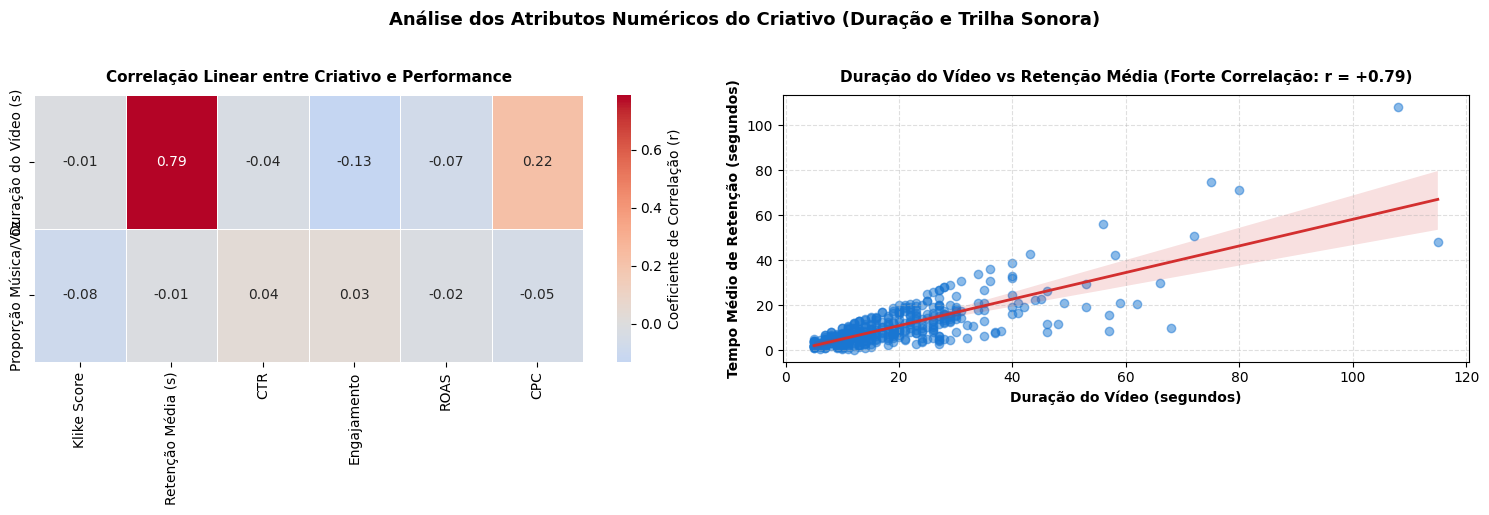

In [ ]:
# Atributos numéricos do criativo e métricas de performance
num_creative = ['video_duration_s', 'music_voice_ratio']
perf_metrics = ['klike_score', 'avg_watch_time_s', 'ctr', 'engagement_rate', 'roas', 'cpc']

# 1. Matriz de Correlação de Pearson
corr_matrix = database[num_creative + perf_metrics].corr().loc[num_creative, perf_metrics]
corr_matrix_styled = corr_matrix.copy()
corr_matrix_styled.index = ['Duração do Vídeo (s)', 'Proporção Música/Voz']
corr_matrix_styled.columns = ['Klike Score', 'Retenção Média (s)', 'CTR', 'Engajamento', 'ROAS', 'CPC']

print("=== CORRELAÇÃO DE PEARSON (ATRIBUTOS NUMÉRICOS vs PERFORMANCE) ===")
display(corr_matrix_styled.round(2))

# 2. Painel Gráfico (Heatmap de Correlação + Dispersão de Duração vs Retenção)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- Gráfico 1: Heatmap das Correlações ---
sns.heatmap(
    corr_matrix_styled, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    center=0, 
    ax=axes[0], 
    cbar_kws={'label': 'Coeficiente de Correlação (r)'}, 
    linewidths=0.5
)
axes[0].set_title('Correlação Linear entre Criativo e Performance', fontweight='bold', fontsize=11, pad=10)

# --- Gráfico 2: Dispersão com Linha de Tendência (Duração vs Retenção) ---
sns.regplot(
    data=database, 
    x='video_duration_s', 
    y='avg_watch_time_s', 
    ax=axes[1],
    scatter_kws={'alpha': 0.5, 'color': '#1976d2'}, 
    line_kws={'color': '#d32f2f', 'linewidth': 2}
)
axes[1].set_title('Duração do Vídeo vs Retenção Média', fontweight='bold', fontsize=11, pad=10)
axes[1].set_xlabel('Duração do Vídeo (segundos)', fontweight='bold')
axes[1].set_ylabel('Tempo Médio de Retenção (segundos)', fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.suptitle('Análise dos Atributos Numéricos do Criativo (Duração e Trilha Sonora)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


Olhando os gráficos acima, pode-se chegar as seguintes conclusões:

1. **`video_duration_s` (Duração do Vídeo):**
   * **Correlação com Retenção Média ($r = +0.79$):** Existe uma correlação linear muito forte e esperada: vídeos mais longos acumulam mais segundos assistidos em valor absoluto.
   * **O Efeito no Custo por Clique ($r = +0.22$ no CPC):** Vídeos mais longos tendem a encarecer o clique. Anúncios curtos (até 20s-30s) geram cliques mais baratos (CPC médio de R$ 0,73 vs R$ 2,88 em vídeos de 30-60s).
   * **Impacto no Klike Score ($r = -0.01$):** A duração isolada não dita a qualidade do criativo por si só — o que realmente importa é o **dinamismo do formato e da plataforma** (um vídeo de 40s pode ser excelente no LinkedIn, mas péssimo no TikTok).

2. **`music_voice_ratio` (Proporção Música vs Voz):**
   * **Correlação Neutra a Levemente Negativa com o Score ($r = -0.08$):** O Desempenho geral do criativo não tem uma correlação muito forte com a proporção de voz e música em um vídeo. Logo, não é uma variável que afeta bastante


## Terceira Etapa: Padrões por plataforma

In [ ]:
# 1. Defini-se o limiar de sucesso (Top Performers: Klike Score >= 70)
top_threshold = 70
top_creatives = database[database['klike_score'] >= top_threshold]

platforms = ['TikTok', 'Meta', 'LinkedIn']
features_check = ['has_hook', 'has_face', 'has_cta', 'has_subtitle']

# 2. Construção da tabela de perfil dos campeões
profile_rows = []
for p in platforms:
    sub = top_creatives[top_creatives['platform'] == p]
    
    profile_rows.append({
        'Plataforma': p,
        'Quantidade': len(sub),
        'Hook Presente (%)': f"{(sub['has_hook'] == True).mean() * 100:.1f}%",
        'Rosto Presente (%)': f"{(sub['has_face'] == True).mean() * 100:.1f}%",
        'CTA Presente (%)': f"{(sub['has_cta'] == True).mean() * 100:.1f}%",
        'Legenda Presente (%)': f"{(sub['has_subtitle'] == True).mean() * 100:.1f}%",
        'Duração Mediana (s)': f"{sub['video_duration_s'].median():.1f}s",
        'Formato Vencedor': sub['format'].mode()[0],
        'Densidade de Texto': sub['text_density'].mode()[0]
    })

df_top_profile = pd.DataFrame(profile_rows)

print("=== O PERFIL DOS CRIATIVOS TOP PERFORMERS POR PLATAFORMA ===")
display(df_top_profile)


=== O PERFIL DOS CRIATIVOS TOP PERFORMERS POR PLATAFORMA ===


,Plataforma,Quantidade,Hook Presente (%),Rosto Presente (%),CTA Presente (%),Legenda Presente (%),Duração Mediana (s),Formato Vencedor,Densidade de Texto
0,TikTok,57,80.7%,70.2%,73.7%,73.6%,13.0s,vertical,medium
1,Meta,70,92.9%,75.7%,85.7%,71.7%,15.5s,vertical,medium
2,LinkedIn,15,86.7%,86.7%,93.3%,83.3%,24.5s,horizontal,medium


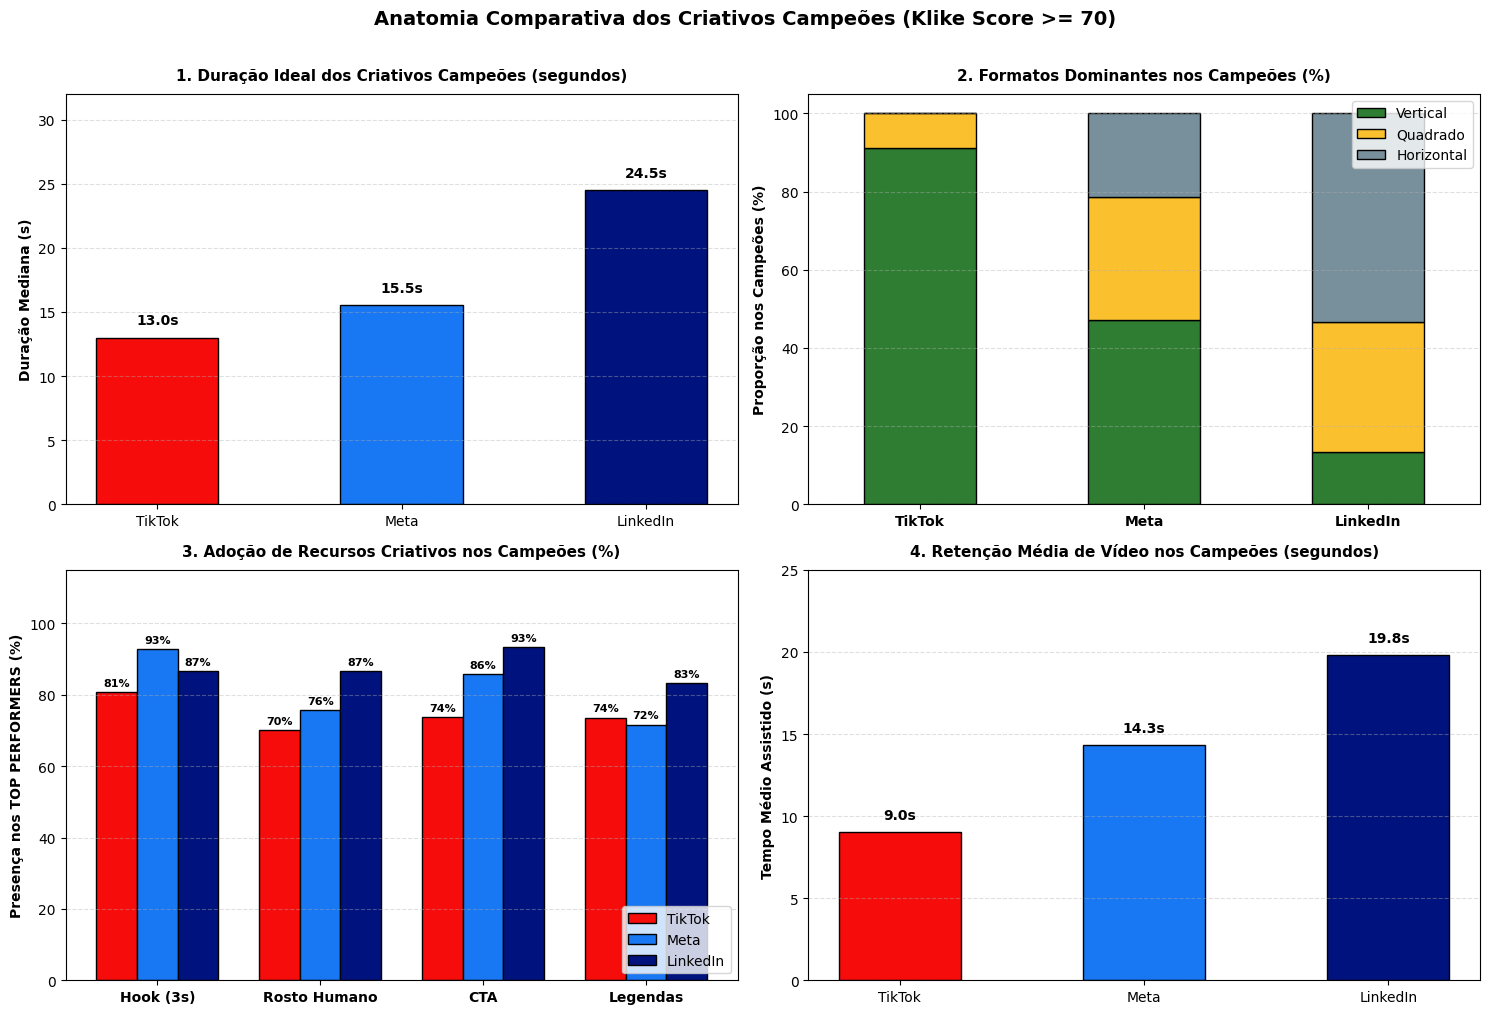

In [ ]:
# Filtra anúncios com nota igual ou superior a 70 (o grupo de excelência criativa)
top_threshold = 70
top_creatives = database[database['klike_score'] >= top_threshold]

# Lista padronizada das redes sociais analisadas e suas cores de identidade visual:
# Vermelho (TikTok), Azul Claro (Meta/Facebook) e Azul Marinho Corporativo (LinkedIn)
platforms = ['TikTok', 'Meta', 'LinkedIn']
colors_plat = ['#F70C0C', '#1877f2', '#00127D']

# Criação da grade 2x2 para o painel comparativo das plataformas
fig, axes = plt.subplots(2, 2, figsize=(15, 10))


# Usar a mediana para evitar distorções de vídeos extremamente longos (outliers)
top_durations = [top_creatives[top_creatives['platform'] == p]['video_duration_s'].median() for p in platforms]

bars1 = axes[0, 0].bar(platforms, top_durations, color=colors_plat, width=0.5, edgecolor='black')
axes[0, 0].set_title('1. Duração Ideal dos Criativos Campeões (segundos)', fontweight='bold', fontsize=11, pad=10)
axes[0, 0].set_ylabel('Duração Mediana (s)', fontweight='bold')
axes[0, 0].set_ylim(0, 32)
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.4)

# Exibe o valor da duração mediana em segundos sobre cada barra
for b in bars1:
    h = b.get_height()
    axes[0, 0].text(b.get_x() + b.get_width()/2., h + 0.8, f"{h:.1f}s", ha='center', va='bottom', fontweight='bold')

# Tabela cruzada normalizada por linha para obter a porcentagem de cada formato dentro de cada plataforma
top_format_dist = (pd.crosstab(top_creatives['platform'], top_creatives['format'], normalize='index') * 100).loc[platforms, ['vertical', 'quadrado', 'horizontal']]

# Plota gráfico de barras empilhadas 100% para evidenciar o mix de proporção de tela
top_format_dist.plot(
    kind='bar', 
    stacked=True, 
    ax=axes[0, 1], 
    color=['#2e7d32', '#fbc02d', '#78909c'], # Verde (Vertical), Amarelo (Quadrado), Cinza (Horizontal)
    edgecolor='black', 
    width=0.5
)
axes[0, 1].set_title('2. Formatos Dominantes nos Campeões (%)', fontweight='bold', fontsize=11, pad=10)
axes[0, 1].set_ylabel('Proporção nos Campeões (%)', fontweight='bold')
axes[0, 1].set_xlabel('')
axes[0, 1].set_xticklabels(platforms, rotation=0, fontweight='bold')
axes[0, 1].set_ylim(0, 105)
axes[0, 1].legend(['Vertical', 'Quadrado', 'Horizontal'], loc='upper right')
axes[0, 1].grid(axis='y', linestyle='--', alpha=0.4)

creative_features = ['has_hook', 'has_face', 'has_cta', 'has_subtitle']
feature_labels = ['Hook (3s)', 'Rosto Humano', 'CTA', 'Legendas']
x_pos = np.arange(len(creative_features))
bar_w = 0.25 

# Itera sobre as 3 plataformas para posicionar as barras lado a lado (offset pelo índice i)
for i, (p, col) in enumerate(zip(platforms, colors_plat)):
    sub = top_creatives[top_creatives['platform'] == p]
    # Calcula a proporção (%) de anúncios que possuem a feature ativa (True)
    pcts = [(sub[f] == True).mean() * 100 for f in creative_features]
    
    bars = axes[1, 0].bar(x_pos + (i - 1) * bar_w, pcts, width=bar_w, label=p, color=col, edgecolor='black')
    
    # Rótulo de porcentagem acima de cada barra do cluster
    for b in bars:
        h = b.get_height()
        axes[1, 0].text(b.get_x() + b.get_width()/2., h + 1.2, f"{h:.0f}%", ha='center', va='bottom', fontsize=8, fontweight='bold')

axes[1, 0].set_title('3. Adoção de Recursos Criativos nos Campeões (%)', fontweight='bold', fontsize=11, pad=10)
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels(feature_labels, fontweight='bold', fontsize=10)
axes[1, 0].set_ylabel('Presença nos TOP PERFORMERS (%)', fontweight='bold')
axes[1, 0].set_ylim(0, 115)
axes[1, 0].legend(loc='lower right')
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.4)

# Média do tempo assistido em segundos para entender a tolerância de atenção por canal
top_retencao = [top_creatives[top_creatives['platform'] == p]['avg_watch_time_s'].mean() for p in platforms]

bars4 = axes[1, 1].bar(platforms, top_retencao, color=colors_plat, width=0.5, edgecolor='black')
axes[1, 1].set_title('4. Retenção Média de Vídeo nos Campeões (segundos)', fontweight='bold', fontsize=11, pad=10)
axes[1, 1].set_ylabel('Tempo Médio Assistido (s)', fontweight='bold')
axes[1, 1].set_ylim(0, 25)
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.4)

# Exibe o tempo médio com 1 casa decimal sobre cada barra
for b in bars4:
    h = b.get_height()
    axes[1, 1].text(b.get_x() + b.get_width()/2., h + 0.6, f"{h:.1f}s", ha='center', va='bottom', fontweight='bold')

# Título global integrador e ajuste fino do espaçamento dos subplots
plt.suptitle('Anatomia Comparativa dos Criativos Campeões (Klike Score >= 70)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()



Ao analisar os gráficos e tabelas acima, podemos chegar nas seguintes conclusões: 

#### 1. TOP PERFORMERS TikTok:
* **Duração Ideal:** **13 segundos** (mediana). Criativos mais longos perdem a retenção imediatamente no feed.
* **Formato Mandatório:** **90% dos campeões são Verticais** (o formato horizontal sequer existe no mix vencedor).
* **Hook nos 3s (81.6%):** A retenção média dos campeões é de apenas **9.0 segundos** — o criativo precisa capturar a atenção instantaneamente e entregar a proposta de valor sem enrolação.
* **Densidade de Texto:** Baixa ou média. O foco é a dinâmica visual e o ritmo sonoro.

#### 2.  TOP PERFORMERS LinkedIn:
* **Duração Ideal:** **24.5 segundos** (quase o dobro do TikTok). O tomador de decisão B2B tolera e valoriza explicações detalhadas de produtos SaaS e cases.
* **Formato Desktop:** Mais de **92% dos campeões são Horizontais (62%) ou Quadrados (31%)**. Apenas 7% são verticais, já que a maior parte do consumo ocorre em telas de computadores no ambiente de trabalho.
* **Retenção Prolongada:** Os melhores anúncios conseguem reter o usuário por **19.8 segundos** (mais do que o dobro do TikTok).
* **Rosto Humano (85.7%) e CTA Claro (92.9%):** Quase unânimes nos campeões. Rosto humano transmite credibilidade corporativa e o CTA é indispensável para qualificar leads.

#### 3.  TOP PERFORMERS Meta:
* **Hook é Praticamente Obrigatório (92.9%):** É a rede onde o gancho nos primeiros 3s tem a maior presença entre os melhores anúncios.
* **Duração e Formato Intermediários:** Duração de **16 segundos** e uso balanceado de formatos verticais (para Reels e Stories) e quadrados (para o feed).